# Portfolio optimisation and the efficient frontier (JSE)

**Question.** Using five years of daily prices for six JSE shares and a JSE Top 40 ETF, which long-only mix of them would have given the best return per unit of risk? How much should those "optimal" weights be trusted, and does the mix keep its edge over equal weight and the Top 40 index on later data the optimiser never saw?

**Approach.**
1. Download adjusted daily prices and compute annualised mean returns and the covariance matrix from 2020 to 2024.
2. Simulate 20,000 random portfolios to see the risk-return cloud.
3. Use `scipy.optimize.minimize` to find the maximum-Sharpe and minimum-variance portfolios, and trace the efficient frontier exactly.
4. Break each portfolio's risk down by asset.
5. Re-estimate the maximum-Sharpe weights on 500 bootstrap resamples of the data to see how stable they are, average them into a "resampled" portfolio, and check how the weights change with the risk-free rate.
6. Hold the weights from January 2025 onwards and compare them with equal weight and the Top 40 ETF out of sample, with standard errors on the Sharpe ratios.
7. Repeat the comparison as a walk-forward test, re-optimising every January on the previous three years, to get more than one out-of-sample period.

The maths lives in `src/portfolio.py` so this notebook can focus on the story. `tests/test_portfolio.py` checks the optimiser against cases with known closed-form answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src import portfolio as pf

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def fmt(df, formats):
    # copy of df with each column turned into formatted strings, for display only
    return df.apply(lambda col: col.map(formats[col.name].format))

## 1. Settings

**Assets.** Six large JSE shares from different sectors, plus the Satrix 40 ETF, which tracks the FTSE/JSE Top 40 index. The ETF already contains most of the six shares, so expect it to be highly correlated with them.

**Periods.** The optimiser only sees the *training* period (2020-01-01 to 2024-12-31). The *test* period starts on 2025-01-01 and is used once, at the end, to see how the chosen weights held up.

**Risk-free rate.** 7.75%, the SARB repo rate after the cut on 21 November 2024, i.e. the rate at the end of the training period. The repo rate moved between 3.5% and 8.25% over 2020 to 2024, so this is a simplification. A 91-day Treasury bill yield would be a closer match to a true risk-free rate; change `RF` to test how sensitive the results are.

In [2]:
ASSETS = {
    "NPN.JO": "Naspers",
    "SBK.JO": "Standard Bank",
    "SOL.JO": "Sasol",
    "MTN.JO": "MTN",
    "AGL.JO": "Anglo American",
    "CPI.JO": "Capitec",
    "STX40.JO": "Satrix 40 ETF",
}
TICKERS = list(ASSETS)

TRAIN_START = "2020-01-01"
TRAIN_END   = "2025-01-01"   # exclusive: training data ends 2024-12-31
TEST_END    = "2026-10-01"   # exclusive: test data runs 2025-01-01 to 2026-09-30

RF = 0.0775                   # annual risk-free rate (SARB repo rate, Nov 2024)
N_SIMULATIONS = 20_000        # random portfolios for the frontier plot
N_BOOT = 500                  # bootstrap resamples for the weight-stability check
BLOCK = 21                    # bootstrap block length in trading days (about a month)
BENCHMARK = "STX40.JO"        # market benchmark for the out-of-sample test

## 2. Data

Prices come from Yahoo Finance through `yfinance`, adjusted for dividends and splits (`auto_adjust=True`) so that returns include dividends. JSE prices are quoted in cents, and Yahoo occasionally has 100x errors in them; `repair=True` asks `yfinance` to fix those.

The first run downloads the data and saves it to `data/prices.csv`. Later runs read that file, so the results do not change each time the notebook is run. Delete the file to download fresh data.

In [3]:
raw = pf.load_prices(TICKERS, TRAIN_START, TEST_END, cache_path="data/prices.csv")
print(f"{len(raw)} rows from {raw.index.min().date()} to {raw.index.max().date()}")
pd.DataFrame({
    "first date": raw.apply(lambda s: s.first_valid_index().date()),
    "last date": raw.apply(lambda s: s.last_valid_index().date()),
    "missing days": raw.isna().sum(),
})

1687 rows from 2020-01-02 to 2026-09-30


,first date,last date,missing days
NPN.JO,2020-01-02,2026-09-30,0
SBK.JO,2020-01-02,2026-09-30,0
SOL.JO,2020-01-02,2026-09-30,0
MTN.JO,2020-01-02,2026-09-30,0
AGL.JO,2020-01-02,2026-09-30,0
CPI.JO,2020-01-02,2026-09-30,0
STX40.JO,2020-01-02,2026-09-30,2


Days when the JSE was closed appear as missing for every ticker and are dropped. Short gaps for a single share (up to 5 days) are filled with the last price. The check below lists any daily move larger than 25%, which is either a real event or a data error and is worth looking at before trusting the results.

In the data saved in `data/prices.csv`, every flagged move falls between 9 March and 7 April 2020, during the COVID crash. Five of the seven flagged days are Sasol, which was also hit by the oil price collapse that began on 9 March 2020, and two are Capitec. They line up with that period and are kept in the data, but some swing back sharply within a day or two, so it is worth checking one or two closing prices against a second source (the JSE or a broker's price history) before relying on them.

In [4]:
prices = pf.clean_prices(raw)
returns_all = pf.daily_returns(prices)

big = returns_all[(returns_all.abs() > 0.25).any(axis=1)]
print(f"Kept {len(prices)} trading days.")
print("Daily moves larger than 25%:" if len(big) else "No daily moves larger than 25%.")
big.round(3) if len(big) else None

Kept 1687 trading days.
Daily moves larger than 25%:


,NPN.JO,SBK.JO,SOL.JO,MTN.JO,AGL.JO,CPI.JO,STX40.JO
Date,,,,,,,
2020-03-09,-0.0440,-0.0490,-0.4660,-0.1510,-0.0910,-0.0250,-0.0650
2020-03-11,0.0060,-0.0260,-0.2640,-0.0170,-0.0080,0.0040,-0.0060
2020-03-12,-0.0800,-0.0560,-0.2940,-0.1340,-0.1320,-0.0570,-0.0980
2020-03-13,-0.0270,-0.0070,0.3640,0.0000,0.0240,-0.0210,-0.0010
2020-03-18,-0.0610,-0.1280,-0.0730,-0.1270,-0.1190,-0.2790,-0.0700
2020-03-20,0.0520,0.0130,-0.1010,-0.0860,0.0950,0.4220,0.0590
2020-04-07,-0.0010,0.0820,0.5350,-0.0060,0.0640,0.0610,0.0240


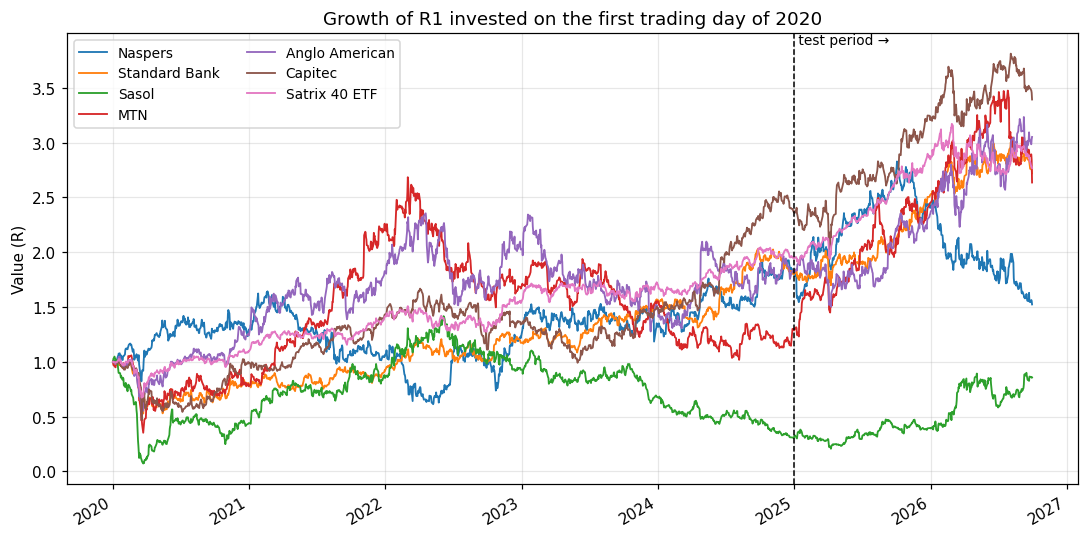

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
(prices / prices.iloc[0]).rename(columns=ASSETS).plot(ax=ax, lw=1.2)
ax.axvline(pd.Timestamp(TRAIN_END), color="black", ls="--", lw=1)
ax.text(pd.Timestamp(TRAIN_END), ax.get_ylim()[1], " test period →", va="top", fontsize=9)
ax.set_title("Growth of R1 invested on the first trading day of 2020")
ax.set_ylabel("Value (R)")
ax.set_xlabel("")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "prices.png")
plt.show()

## 3. Returns, risk and correlation (training period)

Annual mean return = mean daily return × 252. Annual covariance = daily covariance × 252. Volatility is the square root of the diagonal.

In [6]:
train = returns_all.loc[TRAIN_START:TRAIN_END]
train = train[train.index < pd.Timestamp(TRAIN_END)]
test = returns_all[returns_all.index >= pd.Timestamp(TRAIN_END)]
print(f"Training: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:     {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

mean, cov = pf.annualised_stats(train)
vol = np.sqrt(np.diag(cov))

asset_stats = pd.DataFrame({
    "name": pd.Series(ASSETS),
    "annual return": mean,
    "annual volatility": vol,
    "sharpe": (mean - RF) / vol,
}).sort_values("sharpe", ascending=False)
asset_stats

Training: 1249 days (2020-01-03 to 2024-12-31)
Test:     437 days (2025-01-02 to 2026-09-30)


,name,annual return,annual volatility,sharpe
CPI.JO,Capitec,0.2586,0.4145,0.4371
STX40.JO,Satrix 40 ETF,0.1554,0.2067,0.3768
AGL.JO,Anglo American,0.2100,0.4185,0.3167
NPN.JO,Naspers,0.2153,0.4388,0.3140
SBK.JO,Standard Bank,0.1756,0.3378,0.2904
MTN.JO,MTN,0.1557,0.4575,0.1709
SOL.JO,Sasol,0.0209,0.7132,-0.0794


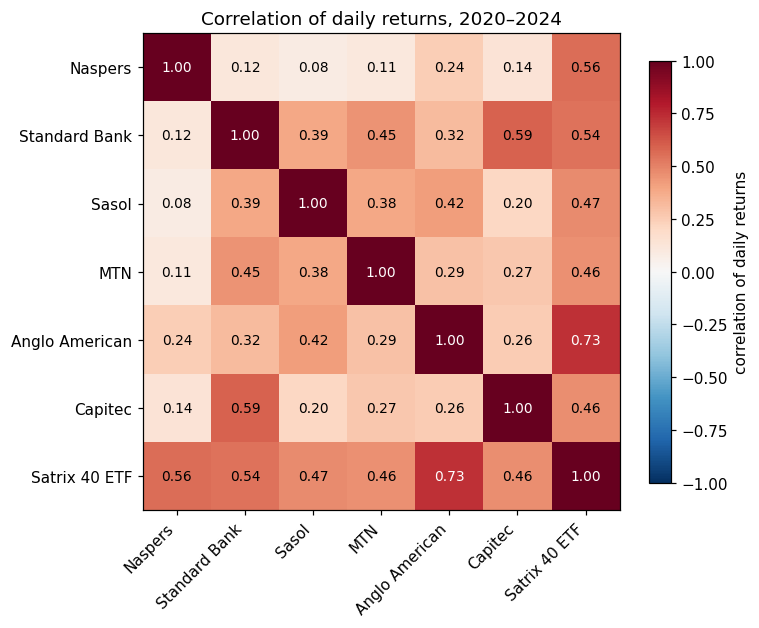

In [7]:
corr = train.corr().rename(index=ASSETS, columns=ASSETS)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation of daily returns")
ax.set_title("Correlation of daily returns, 2020–2024")
fig.tight_layout()
fig.savefig(FIG / "correlation.png")
plt.show()

## 4. Random portfolios

Each simulated portfolio gets random long-only weights that add up to 1. They are drawn from a flat Dirichlet distribution, which covers every possible split evenly. (Drawing uniform random numbers and dividing by their sum, the other common approach, bunches the portfolios around equal weight and leaves the edges of the cloud thin.)

For weights $w$, mean vector $\mu$ and covariance matrix $\Sigma$:

$$\text{return} = w^\top \mu, \qquad \text{volatility} = \sqrt{w^\top \Sigma w}, \qquad \text{Sharpe} = \frac{w^\top \mu - r_f}{\sqrt{w^\top \Sigma w}}$$

In [8]:
sims, sim_weights = pf.simulate_portfolios(mean, cov, RF, n=N_SIMULATIONS, seed=42)
sims.describe().loc[["min", "50%", "max"]]

,return,volatility,sharpe
min,0.0462,0.2146,-0.0496
50%,0.1732,0.2932,0.3356
max,0.2490,0.6323,0.5222


## 5. Optimal portfolios

`scipy.optimize.minimize` (SLSQP) searches over weights between 0 and 1 that add up to 1:

- **Maximum Sharpe** (the tangency portfolio): minimise $-\text{Sharpe}(w)$.
- **Minimum variance**: minimise $w^\top \Sigma w$.
- **Efficient frontier**: for a grid of target returns, minimise $w^\top \Sigma w$ subject to $w^\top \mu = \text{target}$.

Equal weight ($1/7$ in each asset) is the naive benchmark.

In [9]:
k = len(TICKERS)
portfolios = {
    "Max Sharpe": pf.max_sharpe_portfolio(mean, cov, RF),
    "Min variance": pf.min_variance_portfolio(cov),
    "Equal weight": np.full(k, 1 / k),
}
frontier = pf.efficient_frontier(mean, cov, n_points=60)

# The optimiser should do at least as well as the best random portfolio
best_sim = sims["sharpe"].max()
opt = pf.sharpe_ratio(portfolios["Max Sharpe"], mean, cov, RF)
print(f"Best random Sharpe: {best_sim:.4f}   Optimised Sharpe: {opt:.4f}")
assert opt >= best_sim - 1e-9

Best random Sharpe: 0.5222   Optimised Sharpe: 0.5312


In [10]:
summary = pd.DataFrame({name: pf.performance(w, mean, cov, RF) for name, w in portfolios.items()}).T
summary.columns = ["expected return", "volatility", "sharpe"]

weights = pd.DataFrame(portfolios, index=TICKERS).rename(index=ASSETS)

print("Training-period performance (annualised)")
display(fmt(summary, {"expected return": "{:.2%}", "volatility": "{:.2%}", "sharpe": "{:.2f}"}))
print("Weights")
display(weights.map("{:.1%}".format))

Training-period performance (annualised)


,expected return,volatility,sharpe
Max Sharpe,23.54%,29.72%,0.53
Min variance,15.67%,20.61%,0.38
Equal weight,17.02%,27.85%,0.33


Weights


,Max Sharpe,Min variance,Equal weight
Naspers,28.4%,0.0%,14.3%
Standard Bank,0.0%,5.8%,14.3%
Sasol,0.0%,0.0%,14.3%
MTN,0.0%,0.0%,14.3%
Anglo American,22.6%,0.0%,14.3%
Capitec,49.0%,0.1%,14.3%
Satrix 40 ETF,0.0%,94.1%,14.3%


## 6. The efficient frontier

The upper-left edge of the cloud is the efficient frontier: for each level of risk, nothing earns more. The line traced by the optimiser sits exactly on that edge.

The dashed line is the **Capital Market Line**. It starts at the risk-free rate and touches the frontier at the maximum-Sharpe portfolio. If you can lend or borrow at the risk-free rate, any point on this line is reachable by mixing the tangency portfolio with cash, and every point on it beats the frontier below it.

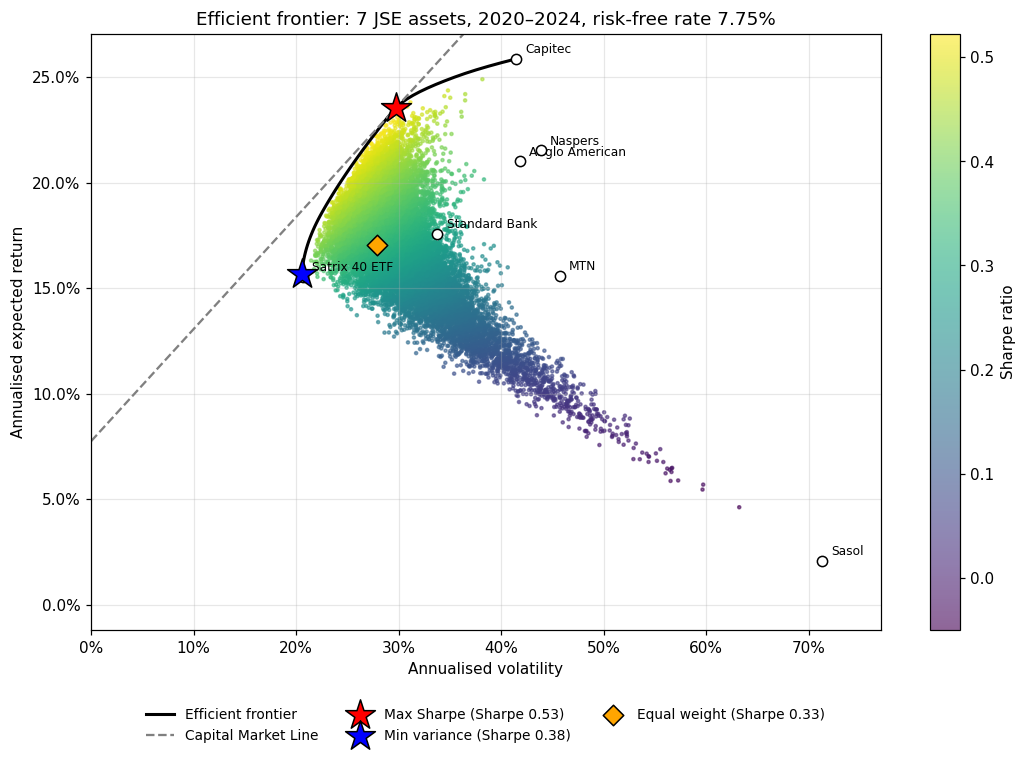

In [11]:
fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(sims["volatility"], sims["return"], c=sims["sharpe"], cmap="viridis", s=4, alpha=0.6)
fig.colorbar(sc, ax=ax, label="Sharpe ratio")
ax.plot(frontier["volatility"], frontier["return"], color="black", lw=2, label="Efficient frontier")

# Capital Market Line
tan = summary.loc["Max Sharpe"]
x = np.linspace(0, max(frontier["volatility"].max(), vol.max()) * 1.05, 100)
ax.plot(x, RF + tan["sharpe"] * x, ls="--", color="grey", lw=1.5, label="Capital Market Line")

# Individual assets
ax.scatter(vol, mean, marker="o", color="white", edgecolor="black", s=45, zorder=4)
for t, v, m in zip(TICKERS, vol, mean):
    ax.annotate(ASSETS[t], (v, m), xytext=(6, 4), textcoords="offset points", fontsize=8)

styles = {"Max Sharpe": ("*", "red", 420), "Min variance": ("*", "blue", 420), "Equal weight": ("D", "orange", 90)}
for name, (marker, colour, size) in styles.items():
    p = summary.loc[name]
    ax.scatter(p["volatility"], p["expected return"], marker=marker, color=colour, edgecolor="black",
               s=size, zorder=5, label=f"{name} (Sharpe {p['sharpe']:.2f})")

ax.set_xlabel("Annualised volatility")
ax.set_ylabel("Annualised expected return")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
# keep the axes on the data; the CML would otherwise stretch the y-axis
y_all = np.concatenate([sims["return"], mean, [RF]])
pad = 0.05 * (y_all.max() - y_all.min())
ax.set_ylim(min(y_all.min(), 0) - pad, y_all.max() + pad)
ax.set_xlim(0, max(sims["volatility"].max(), vol.max()) * 1.08)
ax.set_title(f"Efficient frontier: {k} JSE assets, 2020–2024, risk-free rate {RF:.2%}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=9, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "efficient_frontier.png")
plt.show()

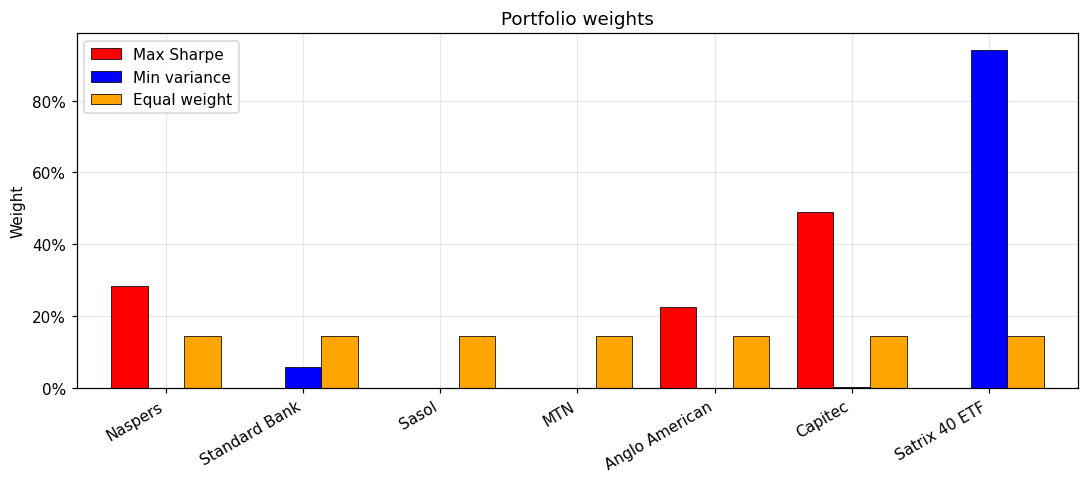

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
weights.plot.bar(ax=ax, color=["red", "blue", "orange"], width=0.8, edgecolor="black", lw=0.5)
ax.set_axisbelow(True)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("Weight")
ax.set_xlabel("")
ax.set_title("Portfolio weights")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIG / "weights.png")
plt.show()

## 7. Where the risk comes from

Weights say where the money is. They do not say where the risk is. Asset $i$ contributes $w_i (\Sigma w)_i$ to the portfolio variance $w^\top \Sigma w$, and these contributions add up to the total. An asset that is volatile and moves with the others contributes more risk than its weight; one that moves against the others can contribute less, or even reduce risk.

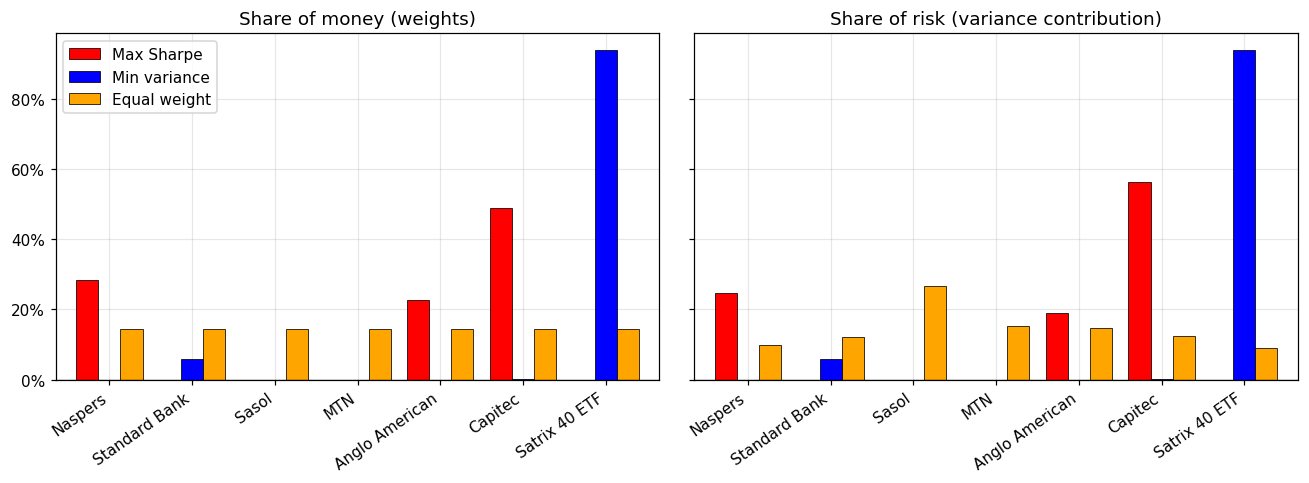

Least volatile single share:  Standard Bank at 33.78%
Average volatility of a share: 46.34%
Satrix 40 ETF:               20.67%
Minimum-variance portfolio:    20.61%


In [13]:
risk = pd.DataFrame(
    {name: pf.risk_contributions(w, cov) for name, w in portfolios.items()}, index=TICKERS
).rename(index=ASSETS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, df, title in [(axes[0], weights, "Share of money (weights)"), (axes[1], risk, "Share of risk (variance contribution)")]:
    df.plot.bar(ax=ax, color=["red", "blue", "orange"], width=0.8, edgecolor="black", lw=0.5, legend=False)
    ax.set_axisbelow(True)
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    plt.setp(ax.get_xticklabels(), ha="right")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "risk_contributions.png")
plt.show()

minvar_vol = summary.loc["Min variance", "volatility"]
shares = asset_stats.drop(index=BENCHMARK, errors="ignore")  # the six shares, without the ETF
print(f"Least volatile single share:  {shares['name'].iloc[shares['annual volatility'].argmin()]} at {shares['annual volatility'].min():.2%}")
print(f"Average volatility of a share: {shares['annual volatility'].mean():.2%}")
if BENCHMARK in asset_stats.index:
    print(f"{ASSETS[BENCHMARK]}:               {asset_stats.loc[BENCHMARK, 'annual volatility']:.2%}")
print(f"Minimum-variance portfolio:    {minvar_vol:.2%}")

The ETF is already a diversified basket of about 40 shares, which is why the minimum-variance portfolio puts almost everything in it and why it is far less volatile than any single share. Compare the minimum-variance volatility with the average share to see how much diversification removes.

## 8. How much should these weights be trusted?

The optimiser treats the 2020–2024 averages as if they were the true expected returns. They are estimates, and noisy ones. If an asset's annual volatility is $\sigma$, a mean estimated from $T$ years of data has a standard error of about $\sigma / \sqrt{T}$. The table below shows the resulting 95% interval, $\pm 1.96\,\sigma/\sqrt{T}$, for each asset. Mean-variance optimisation then amplifies that noise into extreme weights.

In [14]:
years = len(train) / pf.TRADING_DAYS
pd.DataFrame({
    "name": asset_stats["name"],
    "estimated annual return": asset_stats["annual return"].map("{:.1%}".format),
    "95% interval ±": (1.96 * asset_stats["annual volatility"] / np.sqrt(years)).map("{:.1%}".format),
})

,name,estimated annual return,95% interval ±
CPI.JO,Capitec,25.9%,36.5%
STX40.JO,Satrix 40 ETF,15.5%,18.2%
AGL.JO,Anglo American,21.0%,36.8%
NPN.JO,Naspers,21.5%,38.6%
SBK.JO,Standard Bank,17.6%,29.7%
MTN.JO,MTN,15.6%,40.3%
SOL.JO,Sasol,2.1%,62.8%


To measure this, the training returns are resampled with a moving-block bootstrap (blocks of 21 trading days, so volatile and calm spells stay together), the maximum-Sharpe portfolio is re-optimised on each of 500 resamples, and the spread of the weights is recorded. If an asset's weight swings from 0% to 60% across resamples, the single "optimal" number in section 5 should not be taken literally.

In [15]:
boot_w, skipped = pf.bootstrap_max_sharpe(train, RF, n_boot=N_BOOT, block=BLOCK, seed=42)
print(f"{len(boot_w)} usable resamples; {skipped} skipped because no asset beat the risk-free rate.")

boot_table = pd.DataFrame({
    "optimal weight": weights["Max Sharpe"].values,
    "bootstrap median": boot_w.median().values,
    "5th percentile": boot_w.quantile(0.05).values,
    "95th percentile": boot_w.quantile(0.95).values,
    "resamples holding >1%": (boot_w > 0.01).mean().values,
}, index=weights.index)
display(boot_table.map("{:.0%}".format))

498 usable resamples; 2 skipped because no asset beat the risk-free rate.


,optimal weight,bootstrap median,5th percentile,95th percentile,resamples holding >1%
Naspers,28%,12%,0%,86%,60%
Standard Bank,0%,0%,0%,62%,37%
Sasol,0%,0%,0%,28%,23%
MTN,0%,0%,0%,33%,38%
Anglo American,23%,3%,0%,60%,53%
Capitec,49%,21%,0%,94%,71%
Satrix 40 ETF,0%,0%,0%,64%,23%


**A resampled portfolio.** One response to this instability is to average the max-Sharpe weights over all the resamples instead of trusting the single full-sample answer (the idea behind Richard Michaud's resampled efficient frontier). Assets the optimiser picks in most resamples keep a large weight, and assets it picks only occasionally get a small one. The result is tested out of sample alongside the others in section 9.

In [16]:
portfolios["Resampled max Sharpe"] = pf.resampled_max_sharpe(boot_w)
weights["Resampled max Sharpe"] = portfolios["Resampled max Sharpe"]
summary.loc["Resampled max Sharpe"] = list(pf.performance(portfolios["Resampled max Sharpe"], mean, cov, RF).values())

display(weights.map("{:.1%}".format))
display(fmt(summary, {"expected return": "{:.2%}", "volatility": "{:.2%}", "sharpe": "{:.2f}"}))

,Max Sharpe,Min variance,Equal weight,Resampled max Sharpe
Naspers,28.4%,0.0%,14.3%,22.5%
Standard Bank,0.0%,5.8%,14.3%,11.9%
Sasol,0.0%,0.0%,14.3%,4.1%
MTN,0.0%,0.0%,14.3%,7.2%
Anglo American,22.6%,0.0%,14.3%,14.5%
Capitec,49.0%,0.1%,14.3%,29.6%
Satrix 40 ETF,0.0%,94.1%,14.3%,10.2%


,expected return,volatility,sharpe
Max Sharpe,23.54%,29.72%,0.53
Min variance,15.67%,20.61%,0.38
Equal weight,17.02%,27.85%,0.33
Resampled max Sharpe,20.42%,26.45%,0.48


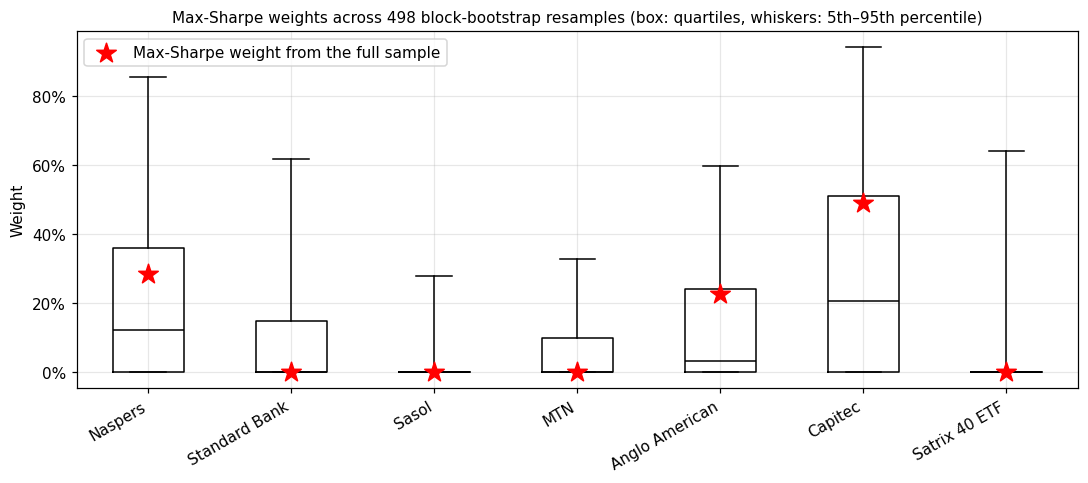

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([boot_w[t] for t in TICKERS], whis=(5, 95), showfliers=False, widths=0.5,
           medianprops={"color": "black"})
ax.scatter(range(1, k + 1), portfolios["Max Sharpe"], color="red", marker="*", s=180, zorder=3,
           label="Max-Sharpe weight from the full sample")
ax.set_xticks(range(1, k + 1), [ASSETS[t] for t in TICKERS], rotation=30, ha="right")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("Weight")
ax.set_title(f"Max-Sharpe weights across {len(boot_w)} block-bootstrap resamples (box: quartiles, whiskers: 5th–95th percentile)")
ax.title.set_fontsize(10)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "bootstrap_weights.png")
plt.show()

**Sensitivity to the risk-free rate.** The tangency portfolio depends on $r_f$. The table re-optimises it for the lowest and highest repo rates of 2020–2024 and two values in between.

In [18]:
rf_rows = {}
for rf in [0.035, 0.06, RF, 0.0825]:
    try:
        w = pf.max_sharpe_portfolio(mean, cov, rf)
    except ValueError:
        continue  # no asset beats this rate
    perf = pf.performance(w, mean, cov, rf)
    rf_rows[f"rf = {rf:.2%}"] = {**dict(zip(weights.index, w)), "Sharpe": perf["sharpe"]}
rf_table = pd.DataFrame(rf_rows)
display(rf_table.apply(lambda r: r.map("{:.2f}".format) if r.name == "Sharpe" else r.map("{:.0%}".format), axis=1))

,rf = 3.50%,rf = 6.00%,rf = 7.75%,rf = 8.25%
Naspers,21%,28%,28%,28%
Standard Bank,4%,4%,0%,0%
Sasol,0%,0%,0%,0%
MTN,1%,1%,0%,0%
Anglo American,13%,22%,23%,22%
Capitec,35%,45%,49%,49%
Satrix 40 ETF,27%,0%,0%,0%
Sharpe,0.68,0.59,0.53,0.51


## 9. Out-of-sample backtest

The weights above were chosen with hindsight: the optimiser saw the 2020–2024 returns. A fairer test is to invest R1 in each portfolio at the close on the last trading day of 2024, never rebalance, and see what happened. The weights drift as prices move, as they would in a real account. The Top 40 ETF on its own is added as a market benchmark: an investor could have bought it instead of doing any of this. No trading costs are included.

The last column is the approximate standard error of each Sharpe ratio (Lo, 2002). With well under two years of data it is large, so a gap between two Sharpe ratios needs to be bigger than about one standard error before it says much.

In [19]:
backtest_portfolios = dict(portfolios)
if BENCHMARK in TICKERS:
    backtest_portfolios[f"{ASSETS[BENCHMARK]} only"] = (np.array(TICKERS) == BENCHMARK).astype(float)

growth = pd.DataFrame({name: pf.buy_and_hold(test, w) for name, w in backtest_portfolios.items()})
start = train.index[-1]  # bought at the close of the last training day
growth = pd.concat([pd.DataFrame(1.0, index=[start], columns=growth.columns), growth])  # start every line at R1

oos = pd.DataFrame({name: pf.backtest_summary(growth[name], RF) for name in growth}).T
oos["sharpe s.e."] = [pf.sharpe_standard_error(s, len(test)) for s in oos["sharpe"]]
OOS_FORMATS = {
    "total return": "{:.2%}", "annualised return (CAGR)": "{:.2%}",
    "volatility": "{:.2%}", "sharpe": "{:.2f}", "max drawdown": "{:.2%}", "sharpe s.e.": "{:.2f}",
}
display(fmt(oos, OOS_FORMATS))

,total return,annualised return (CAGR),volatility,sharpe,max drawdown,sharpe s.e.
Max Sharpe,31.58%,17.14%,20.66%,0.49,-14.39%,0.76
Min variance,42.94%,22.88%,17.81%,0.81,-13.83%,0.76
Equal weight,66.72%,34.28%,18.13%,1.29,-14.92%,0.76
Resampled max Sharpe,43.99%,23.39%,17.68%,0.84,-13.72%,0.76
Satrix 40 ETF only,42.43%,22.62%,18.09%,0.79,-14.57%,0.76


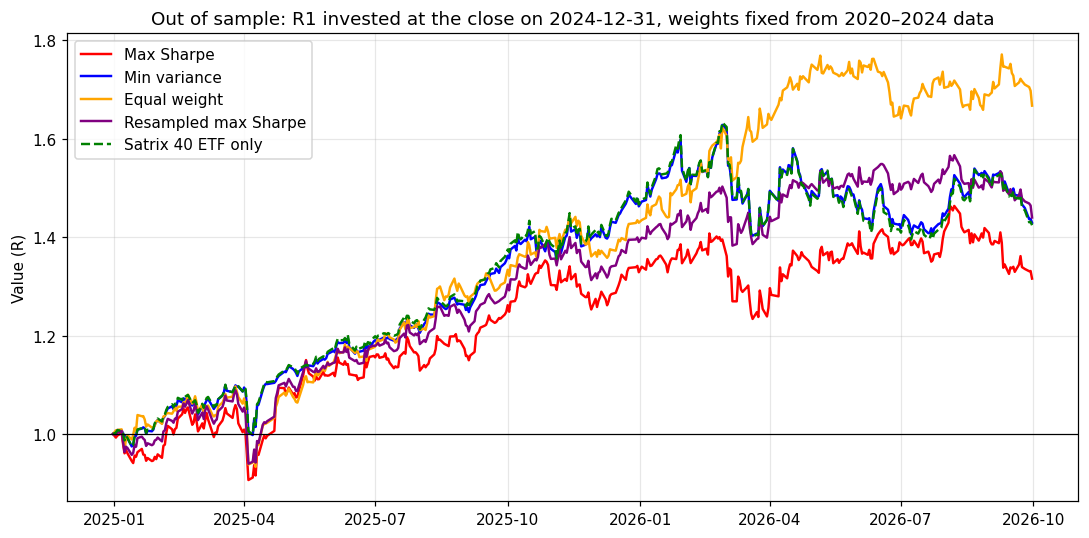

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
COLOURS = {"Max Sharpe": "red", "Min variance": "blue", "Equal weight": "orange",
           "Resampled max Sharpe": "purple", f"{ASSETS.get(BENCHMARK, '')} only": "green"}
for name in growth.columns:
    colour = COLOURS.get(name, "grey")
    ax.plot(growth.index, growth[name], color=colour, lw=1.6, label=name, ls="--" if colour == "green" else "-")
ax.axhline(1, color="black", lw=0.8)
ax.set_title(f"Out of sample: R1 invested at the close on {start.date()}, weights fixed from 2020–2024 data")
ax.set_ylabel("Value (R)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "backtest.png")
plt.show()

## 10. Walk-forward test

Section 9 is one out-of-sample period, 21 months long. A walk-forward test gives more evidence. Every January from 2023 to 2026 each method is re-run using only the previous three years of returns, and the new weights are held until the next January. Every decision uses only data available at the time. Equal weight is reset to $1/7$ each January. If no asset beat the risk-free rate over the previous three years, the max-Sharpe methods hold cash at the risk-free rate for that year, which is what the maximum-Sharpe logic implies.

This uses 2023–2024 data that the main analysis treated as training data, so it is a separate check rather than a continuation of section 9.

In [21]:
WF_DATES = ["2023-01-01", "2024-01-01", "2025-01-01", "2026-01-01"]
LOOKBACK = 3 * pf.TRADING_DAYS

def wf_max_sharpe(history):
    m, c = pf.annualised_stats(history)
    try:
        return pf.max_sharpe_portfolio(m, c, RF)
    except ValueError:
        return None  # nothing beat cash: hold cash

def wf_resampled(history):
    b, _ = pf.bootstrap_max_sharpe(history, RF, n_boot=200, block=BLOCK, seed=0)
    return pf.resampled_max_sharpe(b) if len(b) else None

methods = {
    "Max Sharpe": wf_max_sharpe,
    "Min variance": lambda h: pf.min_variance_portfolio(pf.annualised_stats(h)[1]),
    "Equal weight": lambda h: np.full(h.shape[1], 1 / h.shape[1]),
    "Resampled max Sharpe": wf_resampled,
}
if BENCHMARK in TICKERS:
    methods[f"{ASSETS[BENCHMARK]} only"] = lambda h: (np.array(TICKERS) == BENCHMARK).astype(float)

wf_values, wf_weights = {}, {}
for name, fn in methods.items():
    wf_values[name], wf_weights[name] = pf.walk_forward(returns_all, WF_DATES, LOOKBACK, fn, RF)
wf_growth = pd.DataFrame(wf_values)

wf = pd.DataFrame({name: pf.backtest_summary(wf_growth[name], RF) for name in wf_growth}).T
wf["sharpe s.e."] = [pf.sharpe_standard_error(s, len(wf_growth) - 1) for s in wf["sharpe"]]
print(f"Walk-forward period: {wf_growth.index[1].date()} to {wf_growth.index[-1].date()}")
display(fmt(wf, OOS_FORMATS))

print("Max-Sharpe weights chosen each January (blank = cash)")
display(wf_weights["Max Sharpe"].rename(columns=ASSETS).map(lambda x: "" if pd.isna(x) else f"{x:.0%}"))

Walk-forward period: 2023-01-03 to 2026-09-30


,total return,annualised return (CAGR),volatility,sharpe,max drawdown,sharpe s.e.
Max Sharpe,20.01%,5.04%,21.54%,-0.02,-37.09%,0.52
Min variance,93.39%,19.45%,16.50%,0.69,-13.69%,0.52
Equal weight,88.43%,18.62%,18.22%,0.60,-20.06%,0.52
Resampled max Sharpe,38.72%,9.22%,19.29%,0.15,-27.74%,0.52
Satrix 40 ETF only,80.11%,17.19%,16.66%,0.57,-14.57%,0.52


Max-Sharpe weights chosen each January (blank = cash)


,Naspers,Standard Bank,Sasol,MTN,Anglo American,Capitec,Satrix 40 ETF
2023-01-01,7%,0%,0%,28%,57%,8%,0%
2024-01-01,0%,48%,2%,28%,0%,0%,22%
2025-01-01,21%,77%,0%,0%,0%,2%,0%
2026-01-01,13%,16%,0%,0%,0%,37%,34%


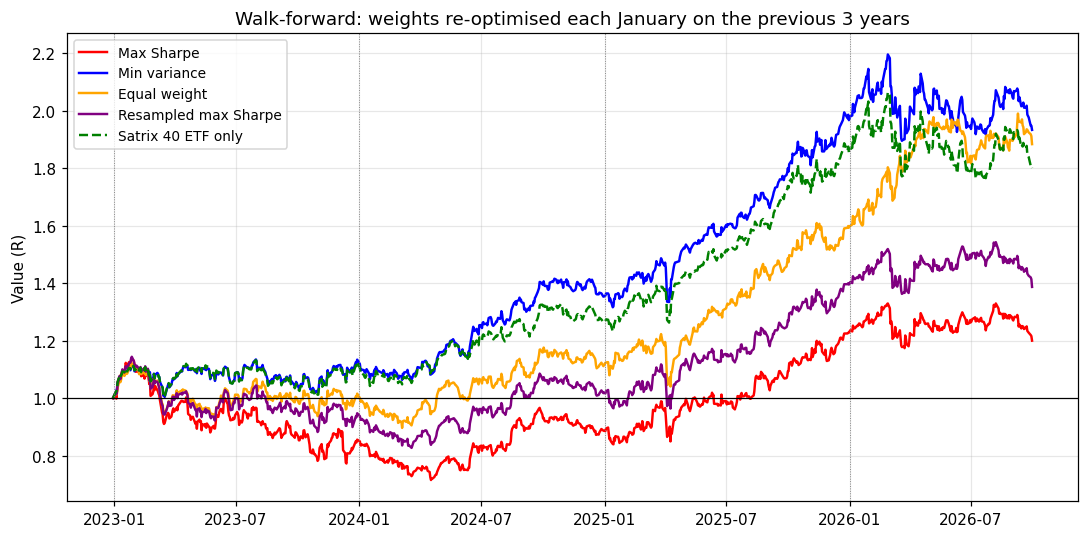

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in wf_growth.columns:
    colour = COLOURS.get(name, "grey")
    ax.plot(wf_growth.index, wf_growth[name], color=colour, lw=1.6, label=name, ls="--" if colour == "green" else "-")
for d in WF_DATES:
    ax.axvline(pd.Timestamp(d), color="grey", lw=0.6, ls=":")
ax.axhline(1, color="black", lw=0.8)
ax.set_title("Walk-forward: weights re-optimised each January on the previous 3 years")
ax.set_ylabel("Value (R)")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "walk_forward.png")
plt.show()

## 11. Conclusion

Over 2020–2024 the maximum-Sharpe portfolio had the best risk-adjusted return on paper: a Sharpe ratio of 0.53, with a 23.5% expected return and 29.7% volatility. Equal weight managed 0.33 and the Satrix 40 ETF 0.38. The optimiser put 49% in Capitec, 28% in Naspers and 23% in Anglo American. Capitec had the best Sharpe ratio of the seven assets (0.44), and the three shares moved fairly independently of each other, with pairwise correlations between 0.14 and 0.26. Combining them brought volatility down to about 30%, against more than 40% for each share on its own. Sasol, with a negative Sharpe ratio and 71% volatility, got nothing.

Diversification did more to cut risk than any single choice. The average share had 46% volatility. The minimum-variance portfolio had 20.6%, and it got there by putting 94% in the ETF, which already spreads its money across about 40 shares.

The bootstrap showed that the max-Sharpe weights should not be taken literally. Across 498 resamples Capitec's weight ranged from 0% to 94%, and Anglo American's median weight was 3%. The 95% interval for Capitec's mean return was ±36.5 percentage points, wider than the 25.9% estimate itself.

Out of sample the ranking reversed. From January 2025 to September 2026 the max-Sharpe portfolio had the lowest Sharpe ratio (0.49), behind the ETF (0.79), minimum variance (0.81), the resampled portfolio (0.84) and equal weight (1.29). Naspers lost 16% over that period, while Sasol and MTN, which the optimiser left out, gained 175% and 105%. The walk-forward test from 2023 gave the same result: max Sharpe grew 5.0% a year with a 37% drawdown, against 19.5% for minimum variance and 18.6% for equal weight. The resampled portfolio sat in between. It beat max Sharpe in both tests but trailed minimum variance and equal weight in the walk-forward test.

These gaps should not be over-read. The standard error of a single Sharpe ratio is 0.76 in the out-of-sample test and 0.52 in the walk-forward test, so most of the differences are around one standard error. What the results do show is a consistent pattern: the methods that leaned hardest on estimated mean returns did worst, and the ones that ignored them, minimum variance and equal weight, did best. Five years of JSE data did not pin down mean returns well enough to optimise on.

## Limitations

- The inputs are past averages. Mean returns in particular are estimated with a lot of noise over five years, and mean-variance optimisation tends to put large weights on whichever assets happened to do well, so the optimal weights are unstable. Past returns do not predict future ones. Sections 8 and 9 measure how much this matters here.
- One constant risk-free rate is used for a period in which the repo rate ranged from 3.5% to 8.25%.
- Volatility treats upside and downside moves the same, and the Sharpe ratio assumes returns are roughly normal, which daily share returns are not (they have fat tails).
- No trading costs, taxes or position limits. Portfolios are long-only and are not rebalanced within a holding period.
- The out-of-sample period is under two years and the walk-forward test under four, so both are short. The Sharpe standard errors show how little a short backtest can separate strategies.
- The block bootstrap keeps short-term clustering but not longer regimes (for example the 2020 crash followed by the recovery).
- Seven assets from one market, and the ETF overlaps heavily with the six shares.

## What I learned

- An optimiser does exactly what it is asked. It found the best Sharpe ratio for 2020–2024, and that portfolio was the worst performer afterwards, because most of its edge came from noise in the mean returns.
- How wide the uncertainty on a mean return is. Five years of daily data sounds like a lot, but with 40% volatility the 95% interval on the annual mean is still about ±35 percentage points.
- Testing the optimiser against cases with a known answer, such as the closed-form tangency portfolio, made it much easier to trust the code before using it on real data.
- Market data needs checking. JSE prices on Yahoo are quoted in cents, `yfinance` needs scikit-learn to repair bad prices, and the large March 2020 moves had to be looked at before being kept.
- A backtest of under two years cannot really separate strategies. Putting standard errors on the Sharpe ratios made that obvious.